# TabM regression

Joint MIDR/MFA regression using the 14 IM-Corr inputs.

## Configuration

In [6]:
import os
import random
import time
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython import get_ipython
from IPython.display import display
from matplotlib import rcParams
from matplotlib.ticker import FuncFormatter, MultipleLocator
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tabm import TabM
from torch.utils.data import DataLoader, TensorDataset

get_ipython().run_line_magic("matplotlib", "inline")

DATA_PATH = Path("data/Data_clean_english.xlsx")
TARGET_COLS = ["MIDR", "MFA"]
SPLIT_SEED = 42
ARCH_COLS = [
    "stories",
    "first_story_height_m",
    "typical_story_height_m",
    "span_length_m",
    "column_section_dim1_m",
    "fundamental_period_rcf_s",
    "beam_section_dim2_m",
]
PDYBRB_COLS = [
    "apdybrb_fy2_mean",
    "apdybrb_fy2_std",
    "apdybrb_fy2_max",
    "apdybrb_fy2_min",
    "apdybrb_fy2_sum",
    "apdybrb_fy2_var",
    "first_stage_yield_ratio",
    "brace_arrangement",
    "apdybrb_activation_disp_mean",
    "apdybrb_activation_disp_std",
    "apdybrb_activation_disp_max",
    "apdybrb_activation_disp_min",
    "apdybrb_activation_disp_sum",
    "apdybrb_activation_disp_var",
]
CAT_COLS = ["stories", "brace_arrangement", "first_stage_yield_ratio"]
CATEGORY_MAPS = {
    "stories": {5: 0, 7: 1, 9: 2, 11: 3},
    "brace_arrangement": {1: 0, 2: 1, 3: 2},
    "first_stage_yield_ratio": {0.4: 0, 0.5: 1},
}
IM_SCHEMES = {
    "IM-Corr": [
        "SI (cm)",
        "EPV (cm/s)",
        "VSI (cm)",
        "SAavg (g)",
        "PGV (cm/s)",
        "PSV (cm/s)",
        "Sa (g)",
        "Vrms (cm/s)",
        "PGA (g)",
        "ASI (cm/s)",
        "EPA (g)",
        "PSA (g)",
        "Ia (m/s)",
        "Arms (g)",
    ]
}
MODEL_NAME = "TabM"
RESULTS_ROOT = Path(os.environ.get("FWK_RESULTS_ROOT", "results"))
OUTPUT_ROOT = RESULTS_ROOT / f"{MODEL_NAME}_IM_experiments"
RUN_DIR = OUTPUT_ROOT / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
SAVE_DIR = RUN_DIR / "IM-Corr"
FIG_DIR = SAVE_DIR / "figures"
TRAIN_SEED = 42
N_EPOCHS = 1500
BATCH_SIZE = 20
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-5
TABM_K = 32
VAL_RATIO = 0.15
VAL_SPLIT_SEED = 42
PATIENCE = 16
CAT_CARDINALITIES = [len(CATEGORY_MAPS[column]) for column in CAT_COLS]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Data preparation

In [7]:
data = pd.read_excel(DATA_PATH)
data.columns = data.columns.astype(str).str.strip()
ratio = pd.to_numeric(
    data["first_stage_yield_ratio"]
    .astype(str)
    .str.strip()
    .str.replace("%", "", regex=False)
)
data["first_stage_yield_ratio"] = np.round(np.where(ratio > 1, ratio / 100, ratio), 6)
for column in ["stories", "brace_arrangement"]:
    data[column] = pd.to_numeric(data[column], errors="raise")

scheme_name = "IM-Corr"
input_cols = ARCH_COLS + PDYBRB_COLS + IM_SCHEMES[scheme_name]
numeric_cols = [column for column in input_cols if column not in CAT_COLS]
numeric = data[numeric_cols].to_numpy(dtype=float)
y_raw = data[TARGET_COLS].to_numpy(dtype=float)
if not np.isfinite(numeric).all() or not np.isfinite(y_raw).all():
    raise ValueError("Inputs or targets contain NaN/Inf.")

category_codes = []
for column in CAT_COLS:
    codes = data[column].map(CATEGORY_MAPS[column])
    if codes.isna().any():
        raise ValueError(f"Unknown or missing categories in {column}.")
    category_codes.append(codes.to_numpy(dtype=np.int64))
categorical = np.column_stack(category_codes)
feature_names = numeric_cols + CAT_COLS

test2_mask = np.zeros(len(data), dtype=bool)
for story, pga in [(5, 0.5), (7, 0.4), (9, 0.3), (11, 0.2)]:
    test2_mask |= (data["stories"].to_numpy() == story) & np.isclose(
        data["PGA (g)"].to_numpy(), pga, rtol=0, atol=1e-6
    )
train_idx, test1_idx = train_test_split(
    np.flatnonzero(~test2_mask), test_size=0.3, random_state=SPLIT_SEED
)
split_indices = {
    "Train": train_idx,
    "Test1": test1_idx,
    "Test2": np.flatnonzero(test2_mask),
}
scaler_x = StandardScaler().fit(numeric[train_idx])
scaler_y = StandardScaler().fit(y_raw[train_idx])
x_num = scaler_x.transform(numeric).astype(np.float32)
y_scaled = scaler_y.transform(y_raw).astype(np.float32)
arrays = {
    name: {
        "x_num": x_num[ids],
        "x_cat": categorical[ids],
        "y": y_scaled[ids],
        "y_raw": y_raw[ids],
        "sample_id": ids,
    }
    for name, ids in split_indices.items()
}
split_manifest = pd.DataFrame({"sample_id": np.arange(len(data)), "split": ""})
for name, ids in split_indices.items():
    split_manifest.loc[ids, "split"] = name

## Training

In [8]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def synchronize_device() -> None:
    if device.type == "cuda":
        torch.cuda.synchronize(device)


def make_loader(arrays: dict, shuffle: bool = False) -> DataLoader:
    dataset = TensorDataset(
        torch.from_numpy(arrays["x_num"]),
        torch.from_numpy(arrays["x_cat"]),
        torch.from_numpy(arrays["y"]),
    )
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
        generator=torch.Generator().manual_seed(TRAIN_SEED),
    )


seed_everything(TRAIN_SEED)
full_train_arrays = arrays["Train"]
fit_idx, val_idx = train_test_split(
    np.arange(len(full_train_arrays["y"])),
    test_size=VAL_RATIO,
    random_state=VAL_SPLIT_SEED,
)
train_arrays = {key: values[fit_idx] for key, values in full_train_arrays.items()}
val_arrays = {key: values[val_idx] for key, values in full_train_arrays.items()}
train_loader = make_loader(train_arrays, shuffle=True)
val_loader = make_loader(val_arrays)
model_kwargs = {
    "n_num_features": len(numeric_cols),
    "cat_cardinalities": CAT_CARDINALITIES,
    "d_out": len(TARGET_COLS),
    "k": TABM_K,
    "arch_type": "tabm-packed",
}
model = TabM.make(**model_kwargs).to(device)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
loss_fn = nn.MSELoss()
history = []
best_val_loss = float("inf")
best_epoch = 0
best_state = None
wait = 0

synchronize_device()
started = time.perf_counter()
for epoch in range(1, N_EPOCHS + 1):
    model.train()
    epoch_loss = torch.zeros((), device=device)
    for x_num_batch, x_cat_batch, y_batch in train_loader:
        x_num_batch = x_num_batch.to(device, non_blocking=True)
        x_cat_batch = x_cat_batch.to(device, non_blocking=True)
        y_batch = y_batch.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        predictions_batch = model(x_num_batch, x_cat_batch)
        loss = loss_fn(
            predictions_batch, y_batch.unsqueeze(1).expand_as(predictions_batch)
        )
        loss.backward()
        optimizer.step()
        epoch_loss += loss.detach() * x_num_batch.size(0)
    average_loss = epoch_loss.item() / len(train_arrays["y"])
    if not np.isfinite(average_loss):
        raise RuntimeError(f"Non-finite training loss at epoch {epoch}.")

    model.eval()
    val_squared_error = 0.0
    val_element_count = 0
    with torch.inference_mode():
        for x_num_batch, x_cat_batch, y_batch in val_loader:
            x_num_batch = x_num_batch.to(device, non_blocking=True)
            x_cat_batch = x_cat_batch.to(device, non_blocking=True)
            y_batch = y_batch.to(device, non_blocking=True)
            val_predictions = model(x_num_batch, x_cat_batch).mean(dim=1)
            val_squared_error += (val_predictions - y_batch).square().sum().item()
            val_element_count += y_batch.numel()
    val_loss = val_squared_error / val_element_count
    if not np.isfinite(val_loss):
        raise RuntimeError(f"Non-finite validation loss at epoch {epoch}.")
    history.append(
        {
            "epoch": epoch,
            "train_mse_scaled": average_loss,
            "val_mse_scaled": val_loss,
        }
    )
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        wait = 0
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
    else:
        wait += 1
    if wait >= PATIENCE:
        break
synchronize_device()
training_seconds = time.perf_counter() - started
epochs_trained = epoch
model.load_state_dict(best_state)
del best_state
model.eval()

TabM(
  (cat_module): _OneHotEncoding()
  (ensemble_view): EnsembleView()
  (backbone): MLPBackboneEnsemble(
    (blocks): ModuleList(
      (0-2): 3 x Sequential(
        (0): LinearEnsemble()
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (output): LinearEnsemble()
)

## Prediction and results

In [9]:
predictions = {}
metric_rows = []
prediction_times = {}
for name in ["Test1", "Test2"]:
    block = arrays[name]
    loader = make_loader(block)
    predictions_scaled = []
    synchronize_device()
    started = time.perf_counter()
    with torch.inference_mode():
        for x_num_batch, x_cat_batch, _ in loader:
            x_num_batch = x_num_batch.to(device, non_blocking=True)
            x_cat_batch = x_cat_batch.to(device, non_blocking=True)
            prediction = model(x_num_batch, x_cat_batch).mean(dim=1)
            predictions_scaled.append(prediction.cpu().numpy())
    synchronize_device()
    prediction_times[name] = time.perf_counter() - started
    prediction = scaler_y.inverse_transform(np.concatenate(predictions_scaled, axis=0))
    if prediction.shape != block["y_raw"].shape or not np.isfinite(prediction).all():
        raise ValueError(f"Invalid predictions for {name}.")
    table = pd.DataFrame({"sample_id": block["sample_id"]})
    for j, target in enumerate(TARGET_COLS):
        truth, estimate = block["y_raw"][:, j], prediction[:, j]
        table[f"{target}_true"] = truth
        table[f"{target}_pred"] = estimate
        metric_rows.append(
            {
                "Split": name,
                "Target": target,
                "R2": r2_score(truth, estimate),
                "RMSE": np.sqrt(mean_squared_error(truth, estimate)),
                "MAE": mean_absolute_error(truth, estimate),
            }
        )
    predictions[name] = table
metrics = pd.DataFrame(metric_rows)
timing = pd.DataFrame(
    [
        {
            "Train_Time_s": training_seconds,
            "Pred_Time_Test1_s": prediction_times["Test1"],
            "Pred_Time_Test2_s": prediction_times["Test2"],
        }
    ]
)
display(metrics, timing)

SAVE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
with pd.ExcelWriter(SAVE_DIR / "results.xlsx", engine="openpyxl") as writer:
    metrics.to_excel(writer, sheet_name="Metrics", index=False)
    timing.to_excel(writer, sheet_name="Timing", index=False)
    pd.DataFrame(history).to_excel(writer, sheet_name="Training_history", index=False)
    for name, table in predictions.items():
        table.to_excel(writer, sheet_name=name, index=False)
split_manifest.to_csv(RUN_DIR / "sample_splits.csv", index=False)
_ = joblib.dump(scaler_x, SAVE_DIR / "scaler_X_tabm.pkl")
_ = joblib.dump(scaler_y, SAVE_DIR / "scaler_Y.pkl")
torch.save(model.to("cpu"), SAVE_DIR / "tabm_model_full.pth")
_ = model.to(device)

,Split,Target,R2,RMSE,MAE
0,Test1,MIDR,0.961736,0.001213,0.000544
1,Test1,MFA,0.974335,0.416586,0.305283
2,Test2,MIDR,0.925912,0.001659,0.000950
3,Test2,MFA,0.909104,0.697021,0.510613


,Train_Time_s,Pred_Time_Test1_s,Pred_Time_Test2_s
0,612.16036,0.477134,0.425371


## Prediction figures

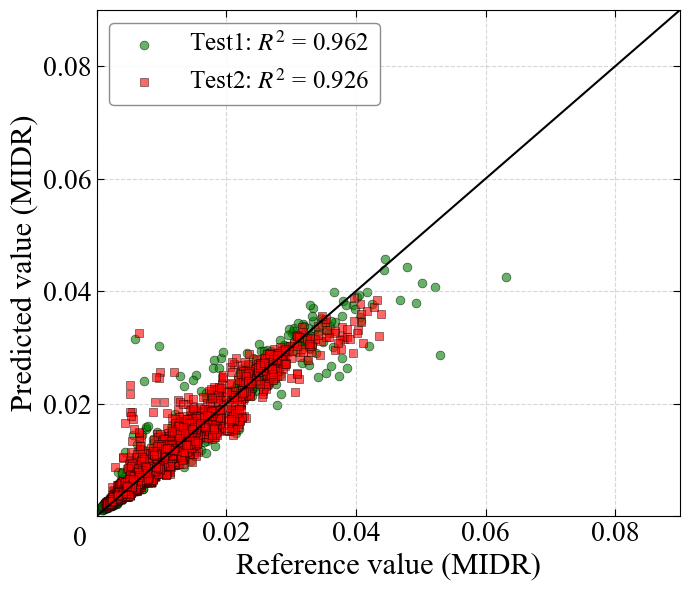

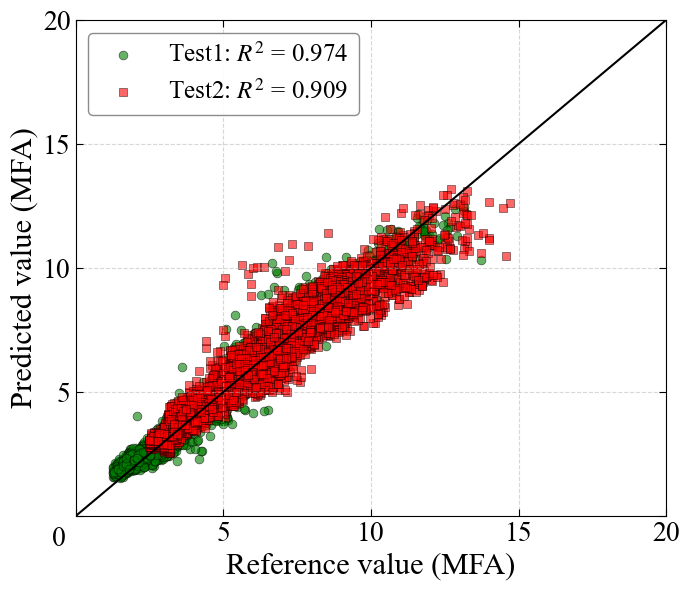

In [10]:
rcParams["font.family"] = "serif"
rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif"]
rcParams["mathtext.fontset"] = "stix"
rcParams["axes.unicode_minus"] = False
for target, limit, step in [("MIDR", 0.09, 0.02), ("MFA", 20, 5)]:
    fig, ax = plt.subplots(figsize=(7, 6))
    for name, color, marker in [("Test1", "green", "o"), ("Test2", "red", "s")]:
        table = predictions[name]
        score = r2_score(table[f"{target}_true"], table[f"{target}_pred"])
        ax.scatter(
            table[f"{target}_true"],
            table[f"{target}_pred"],
            c=color,
            marker=marker,
            s=40,
            alpha=0.6,
            edgecolors="k",
            linewidths=0.5,
            label=rf"{name}: $R^2$ = {score:.3f}",
        )
    ax.plot([0, limit], [0, limit], color="black", linewidth=1.5)
    ax.set(xlim=(0, limit), ylim=(0, limit))
    ax.xaxis.set_major_locator(MultipleLocator(step))
    ax.yaxis.set_major_locator(MultipleLocator(step))
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(
            FuncFormatter(lambda value, _: "" if abs(value) < 1e-12 else f"{value:g}")
        )
    ax.annotate(
        "0",
        xy=(0, 0),
        xycoords="axes fraction",
        xytext=(-7, -7),
        textcoords="offset points",
        ha="right",
        va="top",
        fontsize=20,
        annotation_clip=False,
    )
    ax.set_xlabel(f"Reference value ({target})", fontsize=22)
    ax.set_ylabel(f"Predicted value ({target})", fontsize=22)
    ax.tick_params(labelsize=20, direction="in", top=True, right=True, length=5)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper left", fontsize=18, framealpha=0.9, edgecolor="gray")
    fig.tight_layout()
    for extension in ["png", "pdf"]:
        fig.savefig(
            FIG_DIR / f"TabM_Comparison_{target}_{scheme_name}.{extension}", dpi=300
        )
    display(fig)
    plt.close(fig)